# Phần A — Kiểu dữ liệu của biến gây nhiễu

Triển khai theo [README](README.md), các hàm được định nghĩa trực tiếp trong cell.
ATE thật = 2.0; beta=(0, 0.5, 0.5), gamma=(0.5, 0.5), sigma=1 — khớp mặc định
`distribution_scenario/distribution.py` (baseline.ipynb cũ dùng tau=3 nên không copy hằng số đó).

Bản mặc định chạy **R=200** theo chế độ thử nghiệm của thiết kế. Để chạy **R=1000**,
đổi R ở cell tham số hoặc đặt `RA_VARIABLE_REPS=1000` trước khi khởi động kernel,
rồi Run All. Kết quả hiện có sẽ được ghi lại theo seed và R mới.

Phạm vi: T0–T6, V0–V5. T7, V7 và phần C là tùy chọn chưa triển khai.
Mọi PS trong estimator, balance và ESS đều là logistic **ước lượng**, không dùng PS thật.
Các CI là Wald 95%. Kết quả pilot trong README được xem là giả thuyết, không chép làm kết quả.


## 1. Tham số và thư viện
Môi trường cần numpy, pandas, scipy, statsmodels, matplotlib, IPython và Jupyter, giống các notebook mô phỏng hiện có; không thay dependency của pipeline tiền xử lý.

In [1]:
import os
import json
import warnings
from pathlib import Path
from functools import lru_cache

import numpy as np
import pandas as pd
import scipy
from scipy.special import expit
from scipy.stats import norm
import statsmodels
import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import PerfectSeparationWarning
# Hiển thị và lưu hình ngay trong notebook khi Run All.
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

TAU = 2.0
BETA = (0.0, 0.5, 0.5)
GAMMA = (0.5, 0.5)
SIGMA = 1.0
N_VALUES = (500, 2000)
R_FULL = 1000
R = int(os.environ.get("RA_VARIABLE_REPS", "200"))
SEED = 20261012
N_REF = 200_000
METHODS = ("Naive", "OLS", "IPTW", "AIPW")
Z95 = norm.ppf(0.975)
if R < 2:
    raise ValueError("Monte Carlo cần R >= 2 để tính SD và MC SE.")

# Chạy từ thư mục notebook, gốc dự án, hoặc gốc workspace.
RESULT_DIR = next((p for p in (Path.cwd(), Path.cwd() / "scenario/variable_scenario",
                              Path.cwd() / "ra_causal/scenario/variable_scenario")
                   if (p / "variable_type.ipynb").exists()), None)
if RESULT_DIR is None:
    raise FileNotFoundError("Hãy chạy kernel từ variable_scenario, ra_causal hoặc Seminar.")
RESULT_DIR = RESULT_DIR / "results"
RESULT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
pd.set_option("display.max_columns", None)
print(f"R={R}; n={N_VALUES}; tau={TAU}; results={RESULT_DIR}")


R=200; n=(500, 2000); tau=2.0; results=/home/doan/Seminar/ra_causal/scenario/variable_scenario/results


## 2. Cấu hình và sinh dữ liệu
Hiệu chỉnh gamma0 trên mẫu tham chiếu 200.000 quan sát độc lập cho từng kịch bản. Cache chỉ tránh tính lại cùng một DGP; không hiệu chỉnh theo từng mẫu Monte Carlo.

In [2]:
SCENARIOS = {
    "T0": dict(x2="continuous"),
    "T1": dict(x2="categorical", probs=[.5, .5], g=[0, 1], h=[0, 1]),
    "T2": dict(x2="categorical", probs=[.9, .1], g=[0, 1], h=[0, 1]),
    "T3a": dict(x2="categorical", probs=[.1, .2, .4, .2, .1],
                g=[0, 1, 2, 3, 4], h=[0, 1, 2, 3, 4]),
    "T3b": dict(x2="categorical", probs=[.1, .2, .4, .2, .1],
                g=[0, 1, 1, 0, -1], h=[0, 1, 1, 0, -1]),
    "T4": dict(x2="categorical", probs=[.4, .3, .2, .1],
               g=[0, 1, -1, .5], h=[0, -.5, 1, 1.5]),
    # T5 cố ý tăng confounding/giảm overlap: g không chuẩn hóa Var=0.25.
    "T5": dict(x2="rare_overlap", probs=[.45, .45, .1], h=[-1, 0, 1]),
    "T6": dict(x2="continuous"),
}
ANALYSES = {
    "T0": {"continuous": {"X1": "continuous", "X2": "continuous"}},
    "T1": {"binary": {"X1": "continuous", "X2": "integer"}},
    "T2": {"binary": {"X1": "continuous", "X2": "integer"}},
    "T3a": {a: {"X1": "continuous", "X2": a} for a in ("integer", "dummy")},
    "T3b": {a: {"X1": "continuous", "X2": a} for a in ("integer", "dummy")},
    "T4": {a: {"X1": "continuous", "X2": a} for a in ("dummy", "label")},
    "T5": {"dummy": {"X1": "continuous", "X2": "dummy"}},
    "T6": {"continuous": {"X1": "continuous", "X2": "continuous"},
           "omit_X2": {"X1": "continuous"},
           **{f"binned_{k}": {"X1": "continuous", "X2": f"binned_{k}"}
              for k in (2, 3, 5, 10)}},
}


In [3]:
def standardize_effect(raw, probs):
    """Tâm hóa theo xác suất tổng thể; Var đóng góp = 0.25."""
    raw, p = np.asarray(raw, float), np.asarray(probs, float)
    centered = raw - p @ raw
    return 0.5 * centered / np.sqrt(p @ centered**2)


def _draw_covariates(n, scenario, rng):
    cfg = SCENARIOS[scenario]
    x1 = rng.normal(size=n)
    if cfg["x2"] == "continuous":
        x2 = rng.normal(size=n)
        g2, h2 = GAMMA[1] * x2, BETA[2] * x2
    else:
        x2 = rng.choice(len(cfg["probs"]), size=n, p=cfg["probs"])
        h2 = standardize_effect(cfg["h"], cfg["probs"])[x2]
        g2 = (standardize_effect(cfg["g"], cfg["probs"])[x2]
              if cfg["x2"] != "rare_overlap" else np.zeros(n))
    data = {"X1": x1, "X2": x2}
    lin = GAMMA[0] * x1 + g2
    mu0 = BETA[0] + BETA[1] * x1 + h2
    if cfg.get("has_x3", False):
        rho = cfg.get("rho", 0.)
        x3 = rho * x1 + np.sqrt(1 - rho**2) * rng.normal(size=n)
        data["X3"] = x3
        lin = lin + cfg["g3"] * x3
        mu0 = mu0 + cfg["b3"] * x3
    return data, lin, mu0


def _bisect_intercept(lin, target):
    lo, hi = -50., 50.
    for _ in range(60):
        mid = (lo + hi) / 2
        if expit(mid + lin).mean() < target:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


@lru_cache(maxsize=None)
def _calibrate_gamma0(scenario):
    """Mẫu tham chiếu độc lập, cố định; hiệu chỉnh một lần cho từng DGP."""
    data, lin, _ = _draw_covariates(N_REF, scenario, np.random.default_rng(12345))
    cfg = SCENARIOS[scenario]
    if cfg["x2"] == "rare_overlap":
        # Hiệu chỉnh marginal e trong mức hiếm = .98 và treated toàn mẫu = .50.
        rare = data["X2"] == 2
        p_rare = rare.mean()
        target_common = (0.5 - p_rare * 0.98) / (1 - p_rare)
        gamma0 = _bisect_intercept(lin[~rare], target_common)
        rare_intercept = _bisect_intercept(lin[rare], .98)
        return gamma0, rare_intercept - gamma0
    return _bisect_intercept(lin, .5), 0.


def simulate(n, scenario, seed):
    """Seed con được truyền trực tiếp vào RNG; không dùng RNG toàn cục."""
    if scenario not in SCENARIOS or n < 4:
        raise ValueError("Kịch bản không tồn tại hoặc n < 4.")
    rng = np.random.default_rng(seed)
    data, lin, mu0 = _draw_covariates(n, scenario, rng)
    gamma0, rare_gamma = _calibrate_gamma0(scenario)
    if SCENARIOS[scenario]["x2"] == "rare_overlap":
        lin = lin + rare_gamma * (data["X2"] == 2)
    ps_true = expit(gamma0 + lin)
    a = rng.binomial(1, ps_true)
    eps = rng.normal(0, SIGMA, n)
    df = pd.DataFrame({**data, "A": a, "Y": mu0 + TAU * a + eps})
    # Truth giữ riêng; estimator/diagnostics chỉ nhận dữ liệu quan sát.
    truth = pd.DataFrame({"ps_true": ps_true, "mu0": mu0,
                          "Y0": mu0 + eps, "Y1": mu0 + eps + TAU})
    df.attrs.update(scenario=scenario, gamma0=gamma0, rare_gamma=rare_gamma)
    return df, truth


## 3. Ma trận thiết kế
Cùng design có chặn được dùng cho OLS, PS và outcome của AIPW. Dummy giữ đủ mức theo cấu hình. Với T6, ngưỡng chia nhóm là phân vị tổng thể N(0,1), giúp so sánh các cỡ mẫu trên cùng phép đo.

In [4]:
def make_design(df, spec):
    """Có chặn; dummy có đủ mức theo DGP ngay cả khi mẫu vắng một mức.

    Với T6, dùng ngưỡng phân vị N(0,1) cố định (không ước lượng lại theo mẫu).
    Các biến vắng trong spec được bỏ khỏi mọi mô hình.
    """
    out = pd.DataFrame({"const": np.ones(len(df))}, index=df.index)
    cfg = SCENARIOS[df.attrs["scenario"]]
    for col, encoding in spec.items():
        if encoding in ("continuous", "integer", "label"):
            out[col] = df[col].astype(float)
        elif encoding == "dummy" or encoding.startswith("binned_"):
            if encoding == "dummy":
                levels = range(len(cfg["probs"]))
                values = df[col]
            else:
                k = int(encoding.split("_")[1])
                levels = range(k)
                values = np.digitize(df[col], norm.ppf(np.arange(1, k) / k))
            categories = pd.Series(pd.Categorical(values, categories=levels), index=df.index)
            dummies = pd.get_dummies(categories, prefix=col, drop_first=True, dtype=float)
            out = pd.concat([out, dummies], axis=1)
        else:
            raise ValueError(f"Mã hóa không hỗ trợ: {encoding}")
    return out


def balance_design(df, spec):
    """Balance định tính luôn kiểm tra mọi dummy, kể cả khi fit bằng integer/label."""
    full_spec = dict(spec)
    cfg = SCENARIOS[df.attrs["scenario"]]
    if "X2" in spec and cfg["x2"] != "continuous":
        full_spec["X2"] = "dummy"
    out = make_design(df, full_spec).drop(columns="const")
    if "X2" in spec and cfg["x2"] != "continuous":
        # Thêm dummy mức tham chiếu để không bỏ mất mất cân bằng ở mức này.
        out["X2_0"] = (df.X2 == 0).astype(float)
    elif spec.get("X2", "").startswith("binned_"):
        k = int(spec["X2"].split("_")[1])
        out["X2_0"] = (np.digitize(df.X2, norm.ppf(np.arange(1, k) / k)) == 0).astype(float)
    return out


## 4. Bốn estimator và SE
Naive: Welch; OLS: HC1; IPTW Hájek: IF hiệu chỉnh ước lượng logistic; AIPW: SD của pseudo-outcome / sqrt(n). Logistic không penalize hoặc clip. Fit không xác định/hội tụ được ghi status và NaN, vẫn giữ số lần lặp yêu cầu.

In [5]:
class FitFailure(ValueError):
    pass


def _check_rank(design):
    if np.linalg.matrix_rank(design) < design.shape[1]:
        raise FitFailure("rank_deficient")


def fit_propensity(A, design):
    x = np.asarray(design, float)
    _check_rank(x)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        fit = sm.Logit(A, x).fit(disp=False, maxiter=100)
    if any(issubclass(w.category, PerfectSeparationWarning) for w in caught):
        raise FitFailure("perfect_separation")
    if not fit.mle_retvals.get("converged", False):
        raise FitFailure("ps_not_converged")
    e = np.asarray(fit.predict(x))
    if not np.isfinite(e).all() or np.any((e <= 0) | (e >= 1)):
        raise FitFailure("ps_at_boundary")
    # Không clip hay regularize âm thầm: T5 cần giữ trọng số cực đoan thật sự.
    return e


def est_naive(Y, A, design):
    y1, y0 = Y[A == 1], Y[A == 0]
    if min(len(y1), len(y0)) < 2:
        raise FitFailure("treatment_group_too_small")
    return y1.mean() - y0.mean(), np.sqrt(y1.var(ddof=1)/len(y1) + y0.var(ddof=1)/len(y0))


def est_ols(Y, A, design):
    x = np.column_stack([np.asarray(design), A])
    _check_rank(x)
    fit = sm.OLS(Y, x).fit(cov_type="HC1")
    return fit.params[-1], fit.bse[-1]


def est_iptw(Y, A, design, e_hat=None):
    """Hájek, IF có hiệu chỉnh score/logistic như est_iptw trong baseline.ipynb."""
    x = np.asarray(design, float)
    e = fit_propensity(A, x) if e_hat is None else e_hat
    w1, w0 = A/e, (1-A)/(1-e)
    mu1, mu0 = (w1 @ Y)/w1.sum(), (w0 @ Y)/w0.sum()
    psi = w1*(Y-mu1)/w1.mean() - w0*(Y-mu0)/w0.mean()
    a1 = x.T @ (-w1*(Y-mu1)*(1-e)) / len(Y) / w1.mean()
    a0 = x.T @ (w0*(Y-mu0)*e) / len(Y) / w0.mean()
    information = (x * (e*(1-e))[:, None]).T @ x / len(Y)
    score = x * (A-e)[:, None]
    influence = psi + score @ np.linalg.solve(information, a1-a0)
    return mu1-mu0, influence.std(ddof=1)/np.sqrt(len(Y))


def est_aipw(Y, A, design, e_hat=None):
    x = np.asarray(design, float)
    e = fit_propensity(A, x) if e_hat is None else e_hat
    predictions = {}
    for t in (0, 1):
        xt = x[A == t]
        _check_rank(xt)  # Ô rỗng: không dùng pseudoinverse để giả vờ hệ số xác định.
        if len(xt) <= x.shape[1]:
            raise FitFailure("outcome_group_too_small")
        b = np.linalg.lstsq(xt, Y[A == t], rcond=None)[0]
        predictions[t] = x @ b
    m1, m0 = predictions[1], predictions[0]
    psi = m1-m0 + A*(Y-m1)/e - (1-A)*(Y-m0)/(1-e)
    return psi.mean(), psi.std(ddof=1)/np.sqrt(len(Y))


def estimate_all(df, design):
    Y, A = df.Y.to_numpy(), df.A.to_numpy()
    estimates, status = {}, {}
    failure_types = (FitFailure, np.linalg.LinAlgError, ValueError,
                     sm.tools.sm_exceptions.PerfectSeparationError)
    def record(method, call):
        try:
            value = tuple(float(v) for v in call())
            if not np.isfinite(value).all() or value[1] < 0:
                raise FitFailure("nonfinite_estimate_or_se")
            estimates[method], status[method] = value, "ok"
        except failure_types as exc:
            estimates[method], status[method] = (np.nan, np.nan), str(exc)
    record("Naive", lambda: est_naive(Y, A, design))
    record("OLS", lambda: est_ols(Y, A, design))
    try:
        e = fit_propensity(A, design)
        ps_status = "ok"
    except failure_types as exc:
        e, ps_status = None, str(exc)
    if e is None:
        for method in ("IPTW", "AIPW"):
            estimates[method], status[method] = (np.nan, np.nan), ps_status
    else:
        record("IPTW", lambda: est_iptw(Y, A, design, e))
        record("AIPW", lambda: est_aipw(Y, A, design, e))
    return estimates, e, status, ps_status


## 5. Kiểm tra và chẩn đoán từng kịch bản
SMD nhị phân/dummy dùng mẫu số từ tỷ lệ từng nhóm; biến liên tục dùng mẫu số trước weighting. Không tính VR cho dummy. Balance định tính kiểm tra cả mức tham chiếu và mọi dummy, kể cả analysis dùng integer/label.

In [6]:
def cell_counts(df, spec):
    cfg = SCENARIOS[df.attrs["scenario"]]
    if cfg["x2"] != "continuous":
        values, levels = df.X2, range(len(cfg["probs"]))
    elif spec.get("X2", "").startswith("binned_"):
        k = int(spec["X2"].split("_")[1])
        values, levels = np.digitize(df.X2, norm.ppf(np.arange(1, k)/k)), range(k)
    else:
        return pd.DataFrame()
    return pd.crosstab(df.A, pd.Series(np.asarray(values), index=df.index, name="X2_level")) \
             .reindex(index=[0, 1], columns=list(levels), fill_value=0)


def smd_table(covariates, A, weights=None):
    w = np.ones(len(A)) if weights is None else np.asarray(weights)
    rows = []
    for col in covariates:
        x = covariates[col].to_numpy(float)
        m1 = np.average(x[A == 1], weights=w[A == 1])
        m0 = np.average(x[A == 0], weights=w[A == 0])
        binary = np.isin(x, [0., 1.]).all()
        if binary:
            denom = np.sqrt((m1*(1-m1) + m0*(1-m0))/2)
        else:
            # Dénominateur avant weighting, identique avant/après pour continu.
            denom = np.sqrt((x[A == 1].var(ddof=1)+x[A == 0].var(ddof=1))/2)
        smd = (m1-m0)/denom if denom > 0 else (0. if m1 == m0 else np.inf)
        rows.append({"variable": col, "kind": "binary" if binary else "continuous", "smd": smd})
    return pd.DataFrame(rows).set_index("variable")


def diagnostics(df, spec, e):
    A = df.A.to_numpy()
    counts = cell_counts(df, spec)
    covs = balance_design(df, spec)
    before = smd_table(covs, A)
    result = {"treated_rate": A.mean(), "empty_cells": int((counts == 0).sum().sum()),
              "has_empty_cell": bool((counts == 0).any().any()) if not counts.empty else False,
              "min_cell_count": counts.to_numpy().min() if not counts.empty else np.nan,
              "cell_counts": counts.to_json() if not counts.empty else "{}",
              "max_abs_smd_before": before.smd.abs().max(),
              "e_min": np.nan, "e_max": np.nan, "e_outside": np.nan,
              "max_weight": np.nan, "ess_ratio": np.nan,
              "ess_treated_ratio": np.nan, "ess_control_ratio": np.nan,
              "max_abs_smd_after": np.nan, "x3_smd_after": np.nan,
              "x2_continuous_smd_after": np.nan}
    if e is not None:
        w = A/e + (1-A)/(1-e)
        result.update(e_min=e.min(), e_max=e.max(),
                      e_outside=np.mean((e < .01) | (e > .99)), max_weight=w.max(),
                      ess_ratio=w.sum()**2/(w @ w)/len(w),
                      max_abs_smd_after=smd_table(covs, A, w).smd.abs().max())
        for t, name in ((1, "treated"), (0, "control")):
            wt = w[A == t]
            result[f"ess_{name}_ratio"] = wt.sum()**2/(wt @ wt)/len(wt)
        # Diagnostics de simulation: variable omise disponible au chercheur seulement.
        if "X3" in df:
            result["x3_smd_after"] = smd_table(df[["X3"]], A, w).smd.iloc[0]
        if df.attrs["scenario"] == "T6":
            result["x2_continuous_smd_after"] = smd_table(df[["X2"]], A, w).smd.iloc[0]
    return result


def inspect_case(scenario, n=2000, seed=SEED):
    df, _ = simulate(n, scenario, seed)
    print(f"{scenario}: n={n}, gamma0={df.attrs['gamma0']:.4f}, ATE={TAU}")
    specs = ANALYSES[scenario]
    fig, axes = plt.subplots(1, len(specs), figsize=(max(6, 3*len(specs)), 2.8), squeeze=False)
    for ax, (analysis, spec) in zip(axes[0], specs.items()):
        design = make_design(df, spec)
        estimates, e, status, ps_status = estimate_all(df, design)
        counts = cell_counts(df, spec)
        display(Markdown(f"**{analysis}**"))
        if not counts.empty:
            display(counts)
        display(pd.DataFrame([{"method": m, "est": estimates[m][0], "se": estimates[m][1],
                               "status": status[m]} for m in METHODS]))
        diag = diagnostics(df, spec, e)
        display(pd.DataFrame([{k: v for k, v in diag.items() if k != "cell_counts"}]))
        covs = balance_design(df, spec)
        table = smd_table(covs, df.A.to_numpy()).rename(columns={"smd": "smd_before"})
        if e is not None:
            A = df.A.to_numpy()
            table["smd_after"] = smd_table(covs, A, A/e+(1-A)/(1-e)).smd
            for t in (0, 1):
                ax.hist(e[A == t], bins=np.linspace(0, 1, 31), alpha=.5, label=f"A={t}")
        else:
            ax.text(.5, .5, ps_status, ha="center", transform=ax.transAxes)
        display(table)
        ax.set(title=analysis, xlabel="Propensity score ước lượng", xlim=(0, 1))
        if e is not None:
            ax.legend(frameon=False)
    fig.suptitle(scenario)
    fig.tight_layout()
    plt.show()


In [7]:
# Kiểm tra tính tái lập, consistency, chặn và các SE trên baseline.
baseline = next(iter(SCENARIOS))
d1, t1 = simulate(500, baseline, 42)
d2, t2 = simulate(500, baseline, 42)
pd.testing.assert_frame_equal(d1, d2)
pd.testing.assert_frame_equal(t1, t2)
d3, _ = simulate(500, baseline, 43)
assert not d1.equals(d3)
np.testing.assert_allclose(t1.Y1-t1.Y0, TAU)
np.testing.assert_allclose(d1.Y, np.where(d1.A == 1, t1.Y1, t1.Y0))
for scenario, cfg in SCENARIOS.items():
    d, _ = simulate(500, scenario, 42)
    for spec in ANALYSES[scenario].values():
        design = make_design(d, spec)
        assert np.all(design.iloc[:, 0] == 1) and design.columns.is_unique
    if "g" in cfg:
        for effect in (cfg["g"], cfg["h"]):
            e = standardize_effect(effect, cfg["probs"])
            np.testing.assert_allclose(np.dot(cfg["probs"], e), 0, atol=1e-12)
            np.testing.assert_allclose(np.dot(cfg["probs"], e**2), .25)
x = make_design(d1, next(iter(ANALYSES[baseline].values())))
est, ps, status, _ = estimate_all(d1, x)
assert all(s == "ok" for s in status.values())
reference = sm.OLS(d1.Y, np.column_stack([x, d1.A])).fit(cov_type="HC1")
np.testing.assert_allclose(est["OLS"], [reference.params.iloc[-1], reference.bse.iloc[-1]])
# SMD nhị phân theo đúng công thức tỷ lệ, không dùng VR.
binary = pd.DataFrame({"dummy": [0, 0, 1, 0, 1, 1]})
a = np.array([0, 0, 0, 1, 1, 1])
np.testing.assert_allclose(smd_table(binary, a).smd.iloc[0], (2/3-1/3)/np.sqrt(2/9))
print("Kiểm tra seed, consistency, chuẩn hóa hiệu ứng, design, HC1 và SMD: PASS")

# Đối chiếu SE IPTW với sandwich của hệ estimating equations chung,
# dùng đạo hàm số độc lập để kiểm tra dấu hiệu chỉnh và chuẩn hóa Hájek.
df_check, _ = simulate(2000, baseline, 113)
x_check = make_design(df_check, next(iter(ANALYSES[baseline].values()))).to_numpy()
y_check, a_check = df_check.Y.to_numpy(), df_check.A.to_numpy()
ps_fit = sm.Logit(a_check, x_check).fit(disp=False)
e_check = ps_fit.predict(x_check)
w1_check, w0_check = a_check/e_check, (1-a_check)/(1-e_check)
mu1_check = (w1_check @ y_check)/w1_check.sum()
mu0_check = (w0_check @ y_check)/w0_check.sum()
theta_check = np.r_[ps_fit.params, mu1_check, mu0_check]
def joint_equations(theta):
    prob = expit(x_check @ theta[:-2])
    return np.column_stack([x_check*(a_check-prob)[:, None],
                            a_check/prob*(y_check-theta[-2]),
                            (1-a_check)/(1-prob)*(y_check-theta[-1])])
step = 1e-5
eye_check = np.eye(len(theta_check))
jacobian = np.column_stack([
    (joint_equations(theta_check + eye_check[j]*step).mean(0)
     - joint_equations(theta_check - eye_check[j]*step).mean(0))/(2*step)
    for j in range(len(theta_check))])
joint_if = np.linalg.solve(jacobian, -joint_equations(theta_check).T).T
sandwich_se = (joint_if[:, -2]-joint_if[:, -1]).std(ddof=1)/np.sqrt(len(y_check))
np.testing.assert_allclose(est_iptw(y_check, a_check, x_check, e_check),
                           [mu1_check-mu0_check, sandwich_se], rtol=1e-7)
# Kiểm tra trực tiếp gamma0 trên đúng mẫu tham chiếu, bao gồm e≈.98 ở T5.
for scenario, cfg in SCENARIOS.items():
    data_check, lin_check, _ = _draw_covariates(N_REF, scenario, np.random.default_rng(12345))
    g0_check, rare_check = _calibrate_gamma0(scenario)
    if cfg["x2"] == "rare_overlap":
        lin_check = lin_check + rare_check*(data_check["X2"] == 2)
    prob_check = expit(g0_check+lin_check)
    np.testing.assert_allclose(prob_check.mean(), .5, atol=1e-10)
    if cfg["x2"] == "rare_overlap":
        np.testing.assert_allclose(prob_check[data_check["X2"] == 2].mean(), .98, atol=1e-10)
child_check = np.random.SeedSequence(7).spawn(2)
child_df0, _ = simulate(500, baseline, child_check[0])
child_df0_again, _ = simulate(500, baseline, child_check[0])
child_df1, _ = simulate(500, baseline, child_check[1])
pd.testing.assert_frame_equal(child_df0, child_df0_again)
assert not child_df0.equals(child_df1)
print("Kiểm tra sandwich IPTW độc lập, calibration và seed con: PASS")


Kiểm tra seed, consistency, chuẩn hóa hiệu ứng, design, HC1 và SMD: PASS
Kiểm tra sandwich IPTW độc lập, calibration và seed con: PASS


In [8]:
# Mức hiếm có ô control rỗng: giữ cột dummy và báo lỗi PS/AIPW.
rare, _ = simulate(500, "T5", 53)
rare.loc[rare.X2 == 2, "A"] = 1
x = make_design(rare, ANALYSES["T5"]["dummy"])
assert "X2_2" in x and (cell_counts(rare, ANALYSES["T5"]["dummy"]) == 0).any().any()
try:
    est_aipw(rare.Y.to_numpy(), rare.A.to_numpy(), x, np.full(len(rare), .5))
except FitFailure as exc:
    assert str(exc) == "rank_deficient"
else:
    raise AssertionError("AIPW phải báo rank deficient khi outcome thiếu mức.")
# Vắng một mức toàn mẫu vẫn giữ nguyên shape của ma trận thiết kế.
missing = rare.loc[rare.X2 != 2].copy()
assert list(make_design(missing, ANALYSES["T5"]["dummy"]).columns) == list(x.columns)
print("Kiểm tra ô rỗng và schema dummy: PASS")


Kiểm tra ô rỗng và schema dummy: PASS


### T0
**Kỳ vọng:** Các estimator điều chỉnh gần không chệch, SE/SD gần 1, coverage gần 0.95; Naive chệch.

T0: n=2000, gamma0=-0.0012, ATE=2.0


**continuous**

,method,est,se,status
0,Naive,2.422115,0.054261,ok
1,OLS,2.005205,0.047065,ok
2,IPTW,2.016445,0.047854,ok
3,AIPW,2.001927,0.046930,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.4995,0,False,NaN,0.452118,0.098221,0.910953,0.0,6.25272,0.906337,0.901605,0.911206,0.025039,NaN,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.379860,0.005472
X2,continuous,0.452118,0.025039


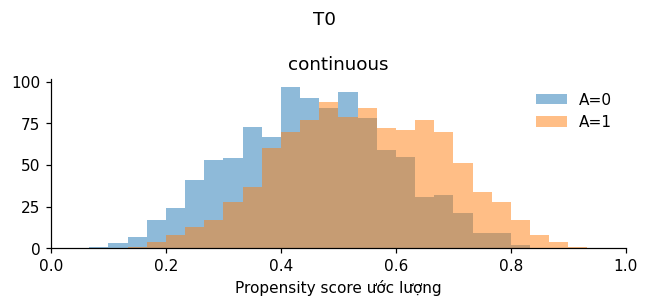

In [9]:
inspect_case("T0")

### T1
**Kỳ vọng:** Nhị phân cân bằng gần baseline khi giữ Var đóng góp = 0.25.

T1: n=2000, gamma0=-0.0003, ATE=2.0


**binary**

X2_level,0,1
A,,
0,622,386
1,392,600


,method,est,se,status
0,Naive,2.440338,0.054683,ok
1,OLS,1.952562,0.047015,ok
2,IPTW,1.942080,0.050243,ok
3,AIPW,1.941931,0.047919,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.496,0,False,386,0.515956,0.095051,0.886085,0.0,10.520685,0.872631,0.866237,0.879528,0.002138,NaN,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.515956,-0.002132
X2_1,binary,0.455188,0.002138
X2_0,binary,-0.455188,-0.002138


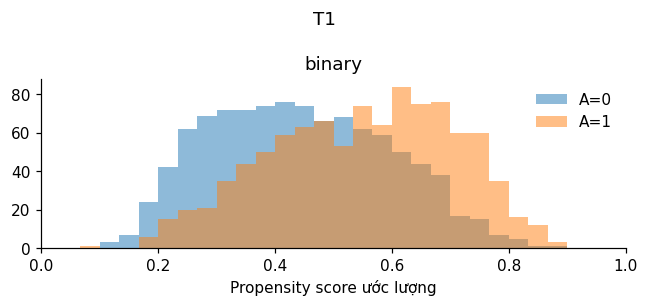

In [10]:
inspect_case("T1")

### T2
**Kỳ vọng:** Mức hiếm làm các ô nhỏ và có thể tăng bất ổn IPTW/AIPW.

T2: n=2000, gamma0=0.0209, ATE=2.0


**binary**

X2_level,0,1
A,,
0,936,39
1,859,166


,method,est,se,status
0,Naive,2.430299,0.054797,ok
1,OLS,1.997616,0.046816,ok
2,IPTW,1.993326,0.049832,ok
3,AIPW,1.981840,0.047108,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.5125,0,False,39,0.425991,0.145959,0.946771,0.0,9.237258,0.889881,0.927283,0.858077,0.01113,NaN,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.425991,0.011130
X2_1,binary,0.413307,0.010866
X2_0,binary,-0.413307,-0.010866


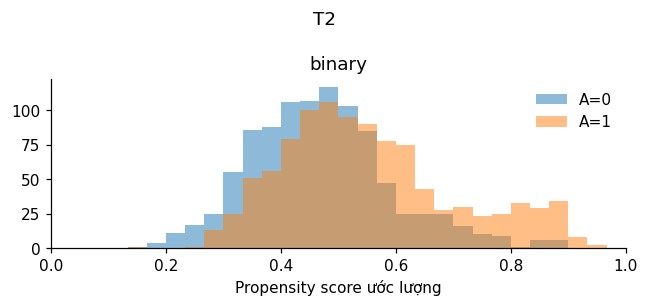

In [11]:
inspect_case("T2")

### T3a
**Kỳ vọng:** Integer và dummy cùng gần không chệch; dummy có thể mất một ít hiệu quả.

T3a: n=2000, gamma0=-0.0005, ATE=2.0


**integer**

X2_level,0,1,2,3,4
A,,,,,
0,154,241,387,147,62
1,59,174,408,225,143


,method,est,se,status
0,Naive,2.501332,0.054714,ok
1,OLS,2.027364,0.046971,ok
2,IPTW,2.015595,0.049896,ok
3,AIPW,2.012946,0.047494,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.5045,0,False,59,0.476563,0.085841,0.916332,0.0,11.95196,0.876884,0.879776,0.874153,0.04943,NaN,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.476563,-0.000264
X2_1,binary,-0.175014,0.045901
X2_2,binary,0.028297,0.001798
X2_3,binary,0.192895,-0.008981
X2_4,binary,0.263661,-0.003420
X2_0,binary,-0.317569,-0.049430


**dummy**

X2_level,0,1,2,3,4
A,,,,,
0,154,241,387,147,62
1,59,174,408,225,143


,method,est,se,status
0,Naive,2.501332,0.054714,ok
1,OLS,2.026509,0.046854,ok
2,IPTW,2.013731,0.049323,ok
3,AIPW,2.012150,0.047122,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.5045,0,False,59,0.476563,0.075241,0.915383,0.0,11.817901,0.874394,0.872522,0.876342,0.004031,NaN,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.476563,0.000306
X2_1,binary,-0.175014,0.000488
X2_2,binary,0.028297,-0.003084
X2_3,binary,0.192895,0.004031
X2_4,binary,0.263661,0.000821
X2_0,binary,-0.317569,-0.001593


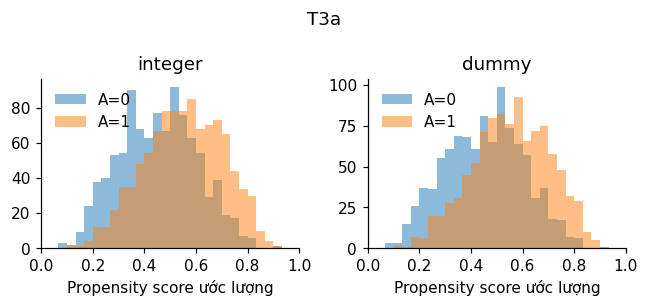

In [12]:
inspect_case("T3a")

### T3b
**Kỳ vọng:** Integer chệch; dummy gần không chệch.

T3b: n=2000, gamma0=-0.0105, ATE=2.0


**integer**

X2_level,0,1,2,3,4
A,,,,,
0,130,178,334,215,151
1,83,237,461,157,54


,method,est,se,status
0,Naive,2.453832,0.054369,ok
1,OLS,2.184875,0.050680,ok
2,IPTW,2.187101,0.051050,ok
3,AIPW,2.186343,0.050885,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.496,0,False,54,0.438878,0.146467,0.826764,0.0,5.526848,0.935737,0.939248,0.932294,0.284991,NaN,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.438878,0.003958
X2_1,binary,0.154077,0.085858
X2_2,binary,0.275027,0.284625
X2_3,binary,-0.141840,-0.056495
X2_4,binary,-0.318922,-0.205237
X2_0,binary,-0.147356,-0.284991


**dummy**

X2_level,0,1,2,3,4
A,,,,,
0,130,178,334,215,151
1,83,237,461,157,54


,method,est,se,status
0,Naive,2.453832,0.054369,ok
1,OLS,2.007643,0.046633,ok
2,IPTW,2.009794,0.047418,ok
3,AIPW,2.003253,0.046903,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.496,0,False,54,0.438878,0.099976,0.850811,0.0,8.599804,0.890999,0.874732,0.908542,0.011378,NaN,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.438878,0.011378
X2_1,binary,0.154077,0.005166
X2_2,binary,0.275027,-0.000300
X2_3,binary,-0.141840,-0.003318
X2_4,binary,-0.318922,-0.000414
X2_0,binary,-0.147356,-0.001701


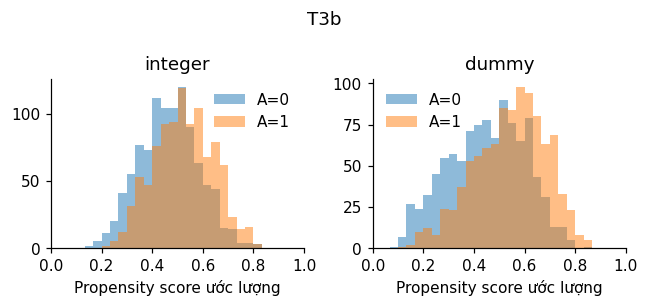

In [13]:
inspect_case("T3b")

### T4
**Kỳ vọng:** Label encoding sai dạng so với dummy; dấu và độ lớn bias phụ thuộc g/h.

T4: n=2000, gamma0=-0.0034, ATE=2.0


**dummy**

X2_level,0,1,2,3
A,,,,
0,443,217,246,83
1,393,370,126,122


,method,est,se,status
0,Naive,2.043180,0.054724,ok
1,OLS,1.892512,0.046187,ok
2,IPTW,1.892581,0.047166,ok
3,AIPW,1.893424,0.046498,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.5055,0,False,83,0.440606,0.095484,0.870982,0.0,7.065289,0.898069,0.899687,0.896731,0.005785,NaN,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.440606,0.004410
X2_1,binary,0.326373,0.004365
X2_2,binary,-0.322621,-0.002025
X2_3,binary,0.121493,-0.005785
X2_0,binary,-0.120235,0.001139


**label**

X2_level,0,1,2,3
A,,,,
0,443,217,246,83
1,393,370,126,122


,method,est,se,status
0,Naive,2.043180,0.054724,ok
1,OLS,1.811337,0.047876,ok
2,IPTW,1.809224,0.048492,ok
3,AIPW,1.807729,0.048141,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.5055,0,False,83,0.440606,0.161281,0.798311,0.0,5.442272,0.94996,0.953738,0.946596,0.342462,NaN,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.440606,0.004482
X2_1,binary,0.326373,0.323498
X2_2,binary,-0.322621,-0.342462
X2_3,binary,0.121493,0.126985
X2_0,binary,-0.120235,-0.105085


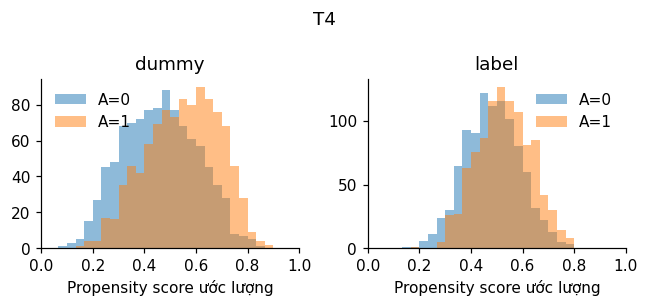

In [14]:
inspect_case("T4")

### T5
**Kỳ vọng:** Trọng số cực đoan, ESS thấp, có thể có ô control rỗng ở mức hiếm.

T5: n=2000, gamma0=-0.2262, ATE=2.0


**dummy**

X2_level,0,1,2
A,,,
0,508,459,3
1,415,413,202


,method,est,se,status
0,Naive,2.463220,0.054768,ok
1,OLS,1.991994,0.048322,ok
2,IPTW,2.004494,0.060025,ok
3,AIPW,1.928979,0.046413,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.515,0,False,3,0.680873,0.131995,0.996797,0.031,65.212655,0.486853,0.892454,0.336108,0.090421,NaN,NaN


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.416124,0.063123
X2_1,binary,-0.145995,-0.030884
X2_2,binary,0.680873,0.090421
X2_0,binary,-0.244047,-0.021014


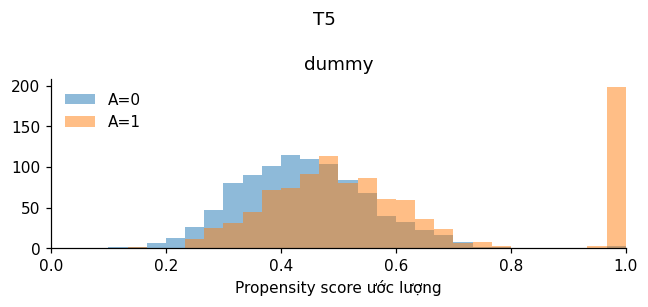

In [15]:
inspect_case("T5")

### T6
**Kỳ vọng:** Bias còn sót giảm khi tăng số nhóm; tăng n không xóa bias do rời rạc hóa.

T6: n=2000, gamma0=-0.0012, ATE=2.0


**continuous**

,method,est,se,status
0,Naive,2.422115,0.054261,ok
1,OLS,2.005205,0.047065,ok
2,IPTW,2.016445,0.047854,ok
3,AIPW,2.001927,0.046930,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.4995,0,False,NaN,0.452118,0.098221,0.910953,0.0,6.25272,0.906337,0.901605,0.911206,0.025039,NaN,0.025039


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.379860,0.005472
X2,continuous,0.452118,0.025039


**omit_X2**

... (19 outputs left out)

X2_level,0,1,2,3,4,5,6,7,8,9
A,,,,,,,,,,
0,144,112,106,96,123,99,97,92,74,58
1,52,74,84,93,107,103,124,118,111,133


,method,est,se,status
0,Naive,2.422115,0.054261,ok
1,OLS,2.011562,0.046946,ok
2,IPTW,2.020249,0.047795,ok
3,AIPW,2.009596,0.046788,ok


,treated_rate,empty_cells,has_empty_cell,min_cell_count,max_abs_smd_before,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after
0,0.4995,0,False,52,0.37986,0.095462,0.898288,0.0,6.242033,0.903946,0.893533,0.914815,0.020859,NaN,0.039459


,kind,smd_before,smd_after
variable,,,
X1,continuous,0.379860,0.006320
X2_1,binary,-0.130488,0.005189
X2_2,binary,-0.074438,-0.001164
X2_3,binary,-0.009610,-0.002230
X2_4,binary,-0.049449,-0.001139
X2_5,binary,0.013945,-0.002282
X2_6,binary,0.086903,0.001689
X2_7,binary,0.085573,-0.004182
X2_8,binary,0.128597,0.000753


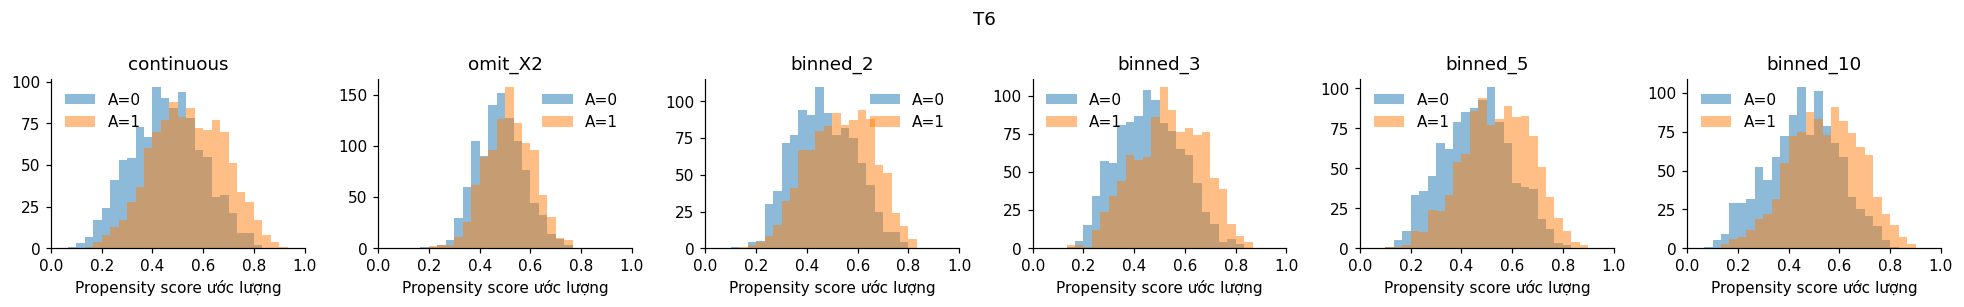

In [16]:
inspect_case("T6")

## 6. Monte Carlo và lưu dữ liệu
`SeedSequence([seed, mã_kịch_bản, n]).spawn(R)` tạo seed con và truyền vào `simulate`. Các analysis của cùng rep dùng cùng dữ liệu. CSV raw có khóa scenario/analysis/n/rep/method; diagnostics lưu riêng một dòng/analysis/rep, bao gồm bảng đếm các ô định tính dạng JSON.

In [17]:
def run_mc(R=R, seed=SEED, scenarios=None, n_values=N_VALUES):
    if R < 2:
        raise ValueError("R phải >= 2.")
    selected = list(SCENARIOS) if scenarios is None else list(scenarios)
    # Cùng rep dùng cùng dữ liệu cho mọi analysis, tạo so sánh ghép cặp.
    # Mã seed ổn định theo scenario/n; không phụ thuộc thứ tự chạy/lọc scenario.
    all_rows, all_diagnostics = [], []
    for scenario in selected:
        scenario_rows, scenario_diagnostics = [], []
        sizes = tuple(n_values) + ((8000,) if scenario == "T6" and 8000 not in n_values else ())
        for n in sizes:
            code = sum((i+1)*ord(c) for i, c in enumerate(scenario))
            children = np.random.SeedSequence([seed, code, n]).spawn(R)
            for rep, child in enumerate(children):
                df, _ = simulate(n, scenario, child)
                for analysis, spec in ANALYSES[scenario].items():
                    design = make_design(df, spec)
                    estimates, e, status, ps_status = estimate_all(df, design)
                    key = dict(scenario=scenario, analysis=analysis, n=n, rep=rep)
                    for method, (est, se) in estimates.items():
                        scenario_rows.append({**key, "method": method, "est": est, "se": se,
                                              "truth": TAU, "status": status[method]})
                    scenario_diagnostics.append({**key, "ps_status": ps_status,
                                                 **diagnostics(df, spec, e)})
            print(f"{scenario}, n={n}: {R} lần lặp hoàn tất", flush=True)
        # Lưu raw trước khi tóm tắt; một dòng/method/rep dù fit thất bại.
        rows, diags = pd.DataFrame(scenario_rows), pd.DataFrame(scenario_diagnostics)
        rows.to_csv(RESULT_DIR / f"{scenario}.csv", index=False)
        diags.to_csv(RESULT_DIR / f"{scenario}_diagnostics.csv", index=False)
        all_rows.append(rows)
        all_diagnostics.append(diags)
    return pd.concat(all_rows, ignore_index=True), pd.concat(all_diagnostics, ignore_index=True)


def summarize_mc(raw):
    rows = []
    for key, group in raw.groupby(["scenario", "analysis", "n", "method"], sort=False):
        ok = group.status.eq("ok") & np.isfinite(group.est) & np.isfinite(group.se)
        valid = group.loc[ok]
        est, se = valid.est.to_numpy(), valid.se.to_numpy()
        truth = valid.truth.to_numpy()
        sd = est.std(ddof=1) if len(est) > 1 else np.nan
        coverage = np.mean(np.abs(est-truth) <= Z95*se) if len(est) else np.nan
        rows.append({**dict(zip(("scenario", "analysis", "n", "method"), key)),
                     "R": len(group), "valid_reps": len(valid), "failed_reps": int((~ok).sum()),
                     "failure_rate": (~ok).mean(),
                     "bias": np.mean(est-truth) if len(est) else np.nan,
                     "mc_se_bias": sd/np.sqrt(len(est)) if len(est) else np.nan,
                     "emp_sd": sd, "mean_se": se.mean() if len(est) else np.nan,
                     "se_sd_ratio": se.mean()/sd if sd > 0 else np.nan,
                     "rmse": np.sqrt(np.mean((est-truth)**2)) if len(est) else np.nan,
                     "coverage": coverage,
                     "mc_se_coverage": np.sqrt(coverage*(1-coverage)/len(est)) if len(est) else np.nan,
                     "mean_ci_width": 2*Z95*se.mean() if len(est) else np.nan})
    return pd.DataFrame(rows)


def summarize_diagnostics(diags):
    grouped = diags.groupby(["scenario", "analysis", "n"], sort=False)
    means = grouped[["treated_rate", "e_min", "e_max", "e_outside", "max_weight", "ess_ratio",
                     "ess_treated_ratio", "ess_control_ratio", "max_abs_smd_before",
                     "max_abs_smd_after", "x3_smd_after", "x2_continuous_smd_after"]].mean()
    means["R"] = grouped.size()
    means["ps_valid_reps"] = grouped.ps_status.apply(lambda s: s.eq("ok").sum())
    means["ps_failed_reps"] = grouped.ps_status.apply(lambda s: s.ne("ok").sum())
    means["empty_cell_reps"] = grouped.has_empty_cell.sum()
    means["empty_cell_rate"] = grouped.has_empty_cell.mean()
    means["min_cell_count_observed"] = grouped.min_cell_count.min()
    return means.reset_index()


def save_metadata(part):
    metadata = {"part": part, "R": R, "R_full": R_FULL, "seed": SEED, "n": list(N_VALUES),
                "T6_extra_n": 8000 if part == "A" else None, "tau": TAU,
                "beta": BETA, "gamma": GAMMA, "sigma": SIGMA, "n_ref": N_REF,
                "calibration_seed": 12345, "bin_cutpoints": "population N(0,1) quantiles",
                "ps": "unpenalized estimated logistic, no clipping",
                "versions": {"numpy": np.__version__, "pandas": pd.__version__,
                             "scipy": scipy.__version__, "statsmodels": statsmodels.__version__},
                "gamma0": {s: _calibrate_gamma0(s)[0] for s in SCENARIOS},
                "rare_gamma": {s: _calibrate_gamma0(s)[1] for s in SCENARIOS}}
    (RESULT_DIR / f"part_{part}_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")


In [18]:
raw, diagnostic_raw = run_mc()
save_metadata("A")
print(f"Đã lưu {len(raw):,} dòng ước lượng; {len(diagnostic_raw):,} dòng diagnostics.")

T0, n=500: 200 lần lặp hoàn tất


T0, n=2000: 200 lần lặp hoàn tất


T1, n=500: 200 lần lặp hoàn tất


T1, n=2000: 200 lần lặp hoàn tất


T2, n=500: 200 lần lặp hoàn tất


T2, n=2000: 200 lần lặp hoàn tất


... (8 outputs left out)

T6, n=500: 200 lần lặp hoàn tất


T6, n=2000: 200 lần lặp hoàn tất


T6, n=8000: 200 lần lặp hoàn tất


Đã lưu 30,400 dòng ước lượng; 7,600 dòng diagnostics.


## 7. Tóm tắt từ CSV
Đọc lại raw đã lưu để có thể tính lại metrics mà không chạy mô phỏng. `valid_reps`, `failed_reps`, `failure_rate` nêu mẫu số; bias, SD, SE, RMSE và coverage tính trên các lần thành công. Khi có failure, coverage này là coverage có điều kiện và cần đọc cùng failure rate. `mc_se_bias=SD/sqrt(valid_reps)`; thêm MC SE của coverage để diễn giải dao động Monte Carlo.

In [18]:
raw = pd.concat([pd.read_csv(RESULT_DIR / f"{s}.csv") for s in SCENARIOS], ignore_index=True)
diagnostic_raw = pd.concat([pd.read_csv(RESULT_DIR / f"{s}_diagnostics.csv") for s in SCENARIOS], ignore_index=True)
summary = summarize_mc(raw)
diagnostic_summary = summarize_diagnostics(diagnostic_raw)
summary.to_csv(RESULT_DIR / "part_A_summary.csv", index=False)
diagnostic_summary.to_csv(RESULT_DIR / "part_A_diagnostic_summary.csv", index=False)
display(summary.round(4))
display(diagnostic_summary.round(4))
# Kiểm tra đầy đủ khóa và số dòng sau khi đọc lại CSV.
assert not raw.duplicated(["scenario", "analysis", "n", "rep", "method"]).any()
assert not diagnostic_raw.duplicated(["scenario", "analysis", "n", "rep"]).any()
assert raw.groupby(["scenario", "analysis", "n", "rep"]).size().eq(len(METHODS)).all()
assert summary.R.eq(R).all()
assert (summary.valid_reps + summary.failed_reps).eq(R).all()
assert summary.valid_reps.eq(raw[raw.status.eq("ok")].groupby(
    ["scenario", "analysis", "n", "method"], sort=False).size().to_numpy()).all()
print("Kiểm tra CSV: khóa duy nhất, đủ method/rep và failure count: PASS")


,scenario,analysis,n,method,R,valid_reps,failed_reps,failure_rate,bias,mc_se_bias,emp_sd,mean_se,se_sd_ratio,rmse,coverage,mc_se_coverage,mean_ci_width
0,T0,continuous,500,Naive,200,200,0,0.0,0.4579,0.0071,0.1010,0.1075,1.0642,0.4688,0.010,0.0070,0.4214
1,T0,continuous,500,OLS,200,200,0,0.0,0.0094,0.0061,0.0858,0.0942,1.0975,0.0861,0.960,0.0139,0.3692
2,T0,continuous,500,IPTW,200,200,0,0.0,0.0083,0.0064,0.0899,0.0972,1.0812,0.0901,0.960,0.0139,0.3811
3,T0,continuous,500,AIPW,200,200,0,0.0,0.0072,0.0062,0.0875,0.0952,1.0882,0.0876,0.955,0.0147,0.3732
4,T0,continuous,2000,Naive,200,200,0,0.0,0.4471,0.0043,0.0610,0.0538,0.8820,0.4512,0.000,0.0000,0.2107
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
147,T6,binned_5,8000,AIPW,200,200,0,0.0,0.0219,0.0018,0.0254,0.0241,0.9476,0.0335,0.825,0.0269,0.0945
148,T6,binned_10,8000,Naive,200,200,0,0.0,0.4480,0.0018,0.0260,0.0269,1.0339,0.4488,0.000,0.0000,0.1055
149,T6,binned_10,8000,OLS,200,200,0,0.0,0.0062,0.0018,0.0249,0.0237,0.9500,0.0256,0.930,0.0180,0.0928
150,T6,binned_10,8000,IPTW,200,200,0,0.0,0.0064,0.0018,0.0260,0.0244,0.9368,0.0267,0.930,0.0180,0.0956


,scenario,analysis,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_before,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after,R,ps_valid_reps,ps_failed_reps,empty_cell_reps,empty_cell_rate,min_cell_count_observed
0,T0,continuous,500,0.4991,0.1100,0.8941,0.0000,7.6369,0.8687,0.8717,0.8716,0.5132,0.0252,NaN,NaN,200,200,0,0,0.000,NaN
1,T0,continuous,2000,0.4994,0.0824,0.9159,0.0000,9.3690,0.8743,0.8737,0.8763,0.4832,0.0124,NaN,NaN,200,200,0,0,0.000,NaN
2,T1,binary,500,0.5010,0.1285,0.8713,0.0000,6.8664,0.8663,0.8706,0.8668,0.5343,0.0199,NaN,NaN,200,200,0,0,0.000,76.0
3,T1,binary,2000,0.5010,0.1109,0.8874,0.0000,7.6433,0.8788,0.8797,0.8790,0.4943,0.0076,NaN,NaN,200,200,0,0,0.000,330.0
4,T2,binary,500,0.5001,0.1637,0.9304,0.0000,10.2038,0.8545,0.9038,0.8206,0.4961,0.0343,NaN,NaN,200,200,0,0,0.000,3.0
5,T2,binary,2000,0.4987,0.1364,0.9469,0.0000,12.5416,0.8642,0.9046,0.8293,0.4763,0.0168,NaN,NaN,200,200,0,0,0.000,22.0
6,T3a,integer,500,0.4992,0.1183,0.8866,0.0000,7.4778,0.8650,0.8677,0.8688,0.4746,0.1168,NaN,NaN,200,200,0,0,0.000,5.0
7,T3a,dummy,500,0.4992,0.1120,0.8911,0.0000,7.9599,0.8575,0.8611,0.8607,0.4746,0.0300,NaN,NaN,200,200,0,0,0.000,5.0
8,T3a,integer,2000,0.4994,0.0922,0.9075,0.0000,8.8004,0.8751,0.8759,0.8758,0.4600,0.0593,NaN,NaN,200,200,0,0,0.000,39.0
9,T3a,dummy,2000,0.4994,0.0912,0.9089,0.0000,8.9983,0.8728,0.8739,0.8735,0.4600,0.0154,NaN,NaN,200,200,0,0,0.000,39.0


Kiểm tra CSV: khóa duy nhất, đủ method/rep và failure count: PASS


In [19]:
# Mốc baseline: Naive dự kiến chệch nên chỉ kiểm tra estimator điều chỉnh.
base = summary[(summary.scenario == next(iter(SCENARIOS))) & (summary.method != "Naive")].copy()
base["bias_within_3_mc_se"] = base.bias.abs() <= 3*base.mc_se_bias
base["coverage_near_95"] = (base.coverage-.95).abs() <= 3*np.sqrt(.95*.05/base.valid_reps)
base["se_sd_near_1"] = base.se_sd_ratio.between(.8, 1.2)
display(base[["n", "method", "bias", "mc_se_bias", "coverage", "se_sd_ratio",
              "bias_within_3_mc_se", "coverage_near_95", "se_sd_near_1"]].round(4))
assert base.failed_reps.eq(0).all()
assert base.bias_within_3_mc_se.all() and base.coverage_near_95.all() and base.se_sd_near_1.all()
print("Baseline Monte Carlo: PASS (dung sai theo MC SE, không ép bias bằng 0).")

,n,method,bias,mc_se_bias,coverage,se_sd_ratio,bias_within_3_mc_se,coverage_near_95,se_sd_near_1
1,500,OLS,0.0094,0.0061,0.960,1.0975,True,True,True
2,500,IPTW,0.0083,0.0064,0.960,1.0812,True,True,True
3,500,AIPW,0.0072,0.0062,0.955,1.0882,True,True,True
5,2000,OLS,-0.0002,0.0038,0.945,0.8846,True,True,True
6,2000,IPTW,-0.0006,0.0039,0.940,0.8900,True,True,True
7,2000,AIPW,-0.0010,0.0037,0.940,0.9007,True,True,True


Baseline Monte Carlo: PASS (dung sai theo MC SE, không ép bias bằng 0).


## 8. Kỳ vọng → Kết quả → Giải thích
Các bảng dưới được sinh từ kết quả thực tế của lần chạy, không suy diễn từ pilot. So sánh độ chệch với MC SE; chênh lệch nhỏ ở R=200 cần xác nhận bằng R=1000.

In [20]:
display(Markdown("### T0\n**Kỳ vọng:** Các estimator điều chỉnh gần không chệch, SE/SD gần 1, coverage gần 0.95; Naive chệch.\n\n**Kết quả:**"))
display(summary.loc[summary.scenario.eq("T0"),
                    ["analysis", "n", "method", "bias", "mc_se_bias", "emp_sd", "mean_se",
                     "se_sd_ratio", "coverage", "mc_se_coverage", "failed_reps"]].round(4))
display(diagnostic_summary.loc[diagnostic_summary.scenario.eq("T0")].round(4))
display(Markdown("**Giải thích:** DGP và mô hình điều chỉnh đều tuyến tính đúng dạng."))

### T0
**Kỳ vọng:** Các estimator điều chỉnh gần không chệch, SE/SD gần 1, coverage gần 0.95; Naive chệch.

**Kết quả:**

,analysis,n,method,bias,mc_se_bias,emp_sd,mean_se,se_sd_ratio,coverage,mc_se_coverage,failed_reps
0,continuous,500,Naive,0.4579,0.0071,0.1010,0.1075,1.0642,0.010,0.0070,0
1,continuous,500,OLS,0.0094,0.0061,0.0858,0.0942,1.0975,0.960,0.0139,0
2,continuous,500,IPTW,0.0083,0.0064,0.0899,0.0972,1.0812,0.960,0.0139,0
3,continuous,500,AIPW,0.0072,0.0062,0.0875,0.0952,1.0882,0.955,0.0147,0
4,continuous,2000,Naive,0.4471,0.0043,0.0610,0.0538,0.8820,0.000,0.0000,0
5,continuous,2000,OLS,-0.0002,0.0038,0.0533,0.0472,0.8846,0.945,0.0161,0
6,continuous,2000,IPTW,-0.0006,0.0039,0.0548,0.0488,0.8900,0.940,0.0168,0
7,continuous,2000,AIPW,-0.0010,0.0037,0.0530,0.0477,0.9007,0.940,0.0168,0


,scenario,analysis,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_before,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after,R,ps_valid_reps,ps_failed_reps,empty_cell_reps,empty_cell_rate,min_cell_count_observed
0,T0,continuous,500,0.4991,0.1100,0.8941,0.0,7.6369,0.8687,0.8717,0.8716,0.5132,0.0252,NaN,NaN,200,200,0,0,0.0,NaN
1,T0,continuous,2000,0.4994,0.0824,0.9159,0.0,9.3690,0.8743,0.8737,0.8763,0.4832,0.0124,NaN,NaN,200,200,0,0,0.0,NaN


**Giải thích:** DGP và mô hình điều chỉnh đều tuyến tính đúng dạng.

In [21]:
display(Markdown("### T1\n**Kỳ vọng:** Nhị phân cân bằng gần baseline khi giữ Var đóng góp = 0.25.\n\n**Kết quả:**"))
display(summary.loc[summary.scenario.eq("T1"),
                    ["analysis", "n", "method", "bias", "mc_se_bias", "emp_sd", "mean_se",
                     "se_sd_ratio", "coverage", "mc_se_coverage", "failed_reps"]].round(4))
display(diagnostic_summary.loc[diagnostic_summary.scenario.eq("T1")].round(4))
display(Markdown("**Giải thích:** Hiệu ứng theo mức được tâm hóa và chuẩn hóa; mã 0/1 biểu diễn đúng DGP."))

### T1
**Kỳ vọng:** Nhị phân cân bằng gần baseline khi giữ Var đóng góp = 0.25.

**Kết quả:**

,analysis,n,method,bias,mc_se_bias,emp_sd,mean_se,se_sd_ratio,coverage,mc_se_coverage,failed_reps
8,binary,500,Naive,0.4626,0.0072,0.1023,0.1075,1.0505,0.010,0.0070,0
9,binary,500,OLS,0.0010,0.0066,0.0932,0.0953,1.0225,0.945,0.0161,0
10,binary,500,IPTW,0.0012,0.0068,0.0962,0.0973,1.0112,0.940,0.0168,0
11,binary,500,AIPW,-0.0005,0.0067,0.0948,0.0961,1.0134,0.945,0.0161,0
12,binary,2000,Naive,0.4554,0.0039,0.0546,0.0538,0.9852,0.000,0.0000,0
13,binary,2000,OLS,0.0038,0.0032,0.0453,0.0472,1.0424,0.970,0.0121,0
14,binary,2000,IPTW,0.0056,0.0032,0.0458,0.0481,1.0496,0.965,0.0130,0
15,binary,2000,AIPW,0.0050,0.0032,0.0459,0.0476,1.0380,0.960,0.0139,0


,scenario,analysis,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_before,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after,R,ps_valid_reps,ps_failed_reps,empty_cell_reps,empty_cell_rate,min_cell_count_observed
2,T1,binary,500,0.501,0.1285,0.8713,0.0,6.8664,0.8663,0.8706,0.8668,0.5343,0.0199,NaN,NaN,200,200,0,0,0.0,76.0
3,T1,binary,2000,0.501,0.1109,0.8874,0.0,7.6433,0.8788,0.8797,0.8790,0.4943,0.0076,NaN,NaN,200,200,0,0,0.0,330.0


**Giải thích:** Hiệu ứng theo mức được tâm hóa và chuẩn hóa; mã 0/1 biểu diễn đúng DGP.

In [22]:
display(Markdown("### T2\n**Kỳ vọng:** Mức hiếm làm các ô nhỏ và có thể tăng bất ổn IPTW/AIPW.\n\n**Kết quả:**"))
display(summary.loc[summary.scenario.eq("T2"),
                    ["analysis", "n", "method", "bias", "mc_se_bias", "emp_sd", "mean_se",
                     "se_sd_ratio", "coverage", "mc_se_coverage", "failed_reps"]].round(4))
display(diagnostic_summary.loc[diagnostic_summary.scenario.eq("T2")].round(4))
display(Markdown("**Giải thích:** Cần đọc đồng thời SE/SD, coverage và số lần có ô rỗng; không suy luận chỉ từ bias."))

### T2
**Kỳ vọng:** Mức hiếm làm các ô nhỏ và có thể tăng bất ổn IPTW/AIPW.

**Kết quả:**

,analysis,n,method,bias,mc_se_bias,emp_sd,mean_se,se_sd_ratio,coverage,mc_se_coverage,failed_reps
16,binary,500,Naive,0.4256,0.0075,0.1054,0.1076,1.0207,0.02,0.0099,0
17,binary,500,OLS,-0.0043,0.0064,0.0912,0.0942,1.0325,0.94,0.0168,0
18,binary,500,IPTW,-0.0020,0.0075,0.1062,0.0997,0.9389,0.93,0.0180,0
19,binary,500,AIPW,-0.0051,0.0069,0.0974,0.0955,0.9815,0.95,0.0154,0
20,binary,2000,Naive,0.4376,0.0037,0.0516,0.0539,1.0449,0.00,0.0000,0
21,binary,2000,OLS,0.0029,0.0030,0.0428,0.0471,1.0987,0.97,0.0121,0
22,binary,2000,IPTW,0.0037,0.0033,0.0461,0.0501,1.0858,0.96,0.0139,0
23,binary,2000,AIPW,0.0028,0.0031,0.0438,0.0480,1.0974,0.97,0.0121,0


,scenario,analysis,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_before,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after,R,ps_valid_reps,ps_failed_reps,empty_cell_reps,empty_cell_rate,min_cell_count_observed
4,T2,binary,500,0.5001,0.1637,0.9304,0.0,10.2038,0.8545,0.9038,0.8206,0.4961,0.0343,NaN,NaN,200,200,0,0,0.0,3.0
5,T2,binary,2000,0.4987,0.1364,0.9469,0.0,12.5416,0.8642,0.9046,0.8293,0.4763,0.0168,NaN,NaN,200,200,0,0,0.0,22.0


**Giải thích:** Cần đọc đồng thời SE/SD, coverage và số lần có ô rỗng; không suy luận chỉ từ bias.

In [23]:
display(Markdown("### T3a\n**Kỳ vọng:** Integer và dummy cùng gần không chệch; dummy có thể mất một ít hiệu quả.\n\n**Kết quả:**"))
display(summary.loc[summary.scenario.eq("T3a"),
                    ["analysis", "n", "method", "bias", "mc_se_bias", "emp_sd", "mean_se",
                     "se_sd_ratio", "coverage", "mc_se_coverage", "failed_reps"]].round(4))
display(diagnostic_summary.loc[diagnostic_summary.scenario.eq("T3a")].round(4))
display(Markdown("**Giải thích:** Hiệu ứng tuyến tính theo mức nên integer đã đủ; dummy dùng thêm ba tham số."))

### T3a
**Kỳ vọng:** Integer và dummy cùng gần không chệch; dummy có thể mất một ít hiệu quả.

**Kết quả:**

,analysis,n,method,bias,mc_se_bias,emp_sd,mean_se,se_sd_ratio,coverage,mc_se_coverage,failed_reps
24,integer,500,Naive,0.4588,0.0080,0.1132,0.1073,0.9484,0.010,0.0070,0
25,integer,500,OLS,0.0038,0.0071,0.1011,0.0944,0.9337,0.925,0.0186,0
26,integer,500,IPTW,0.0025,0.0074,0.1044,0.0973,0.9319,0.925,0.0186,0
27,integer,500,AIPW,0.0018,0.0073,0.1031,0.0956,0.9272,0.925,0.0186,0
28,dummy,500,Naive,0.4588,0.0080,0.1132,0.1073,0.9484,0.010,0.0070,0
29,dummy,500,OLS,0.0047,0.0071,0.1011,0.0945,0.9349,0.925,0.0186,0
30,dummy,500,IPTW,0.0037,0.0074,0.1049,0.0972,0.9271,0.930,0.0180,0
31,dummy,500,AIPW,0.0022,0.0073,0.1029,0.0953,0.9259,0.915,0.0197,0
32,integer,2000,Naive,0.4496,0.0038,0.0533,0.0538,1.0091,0.000,0.0000,0
33,integer,2000,OLS,0.0017,0.0034,0.0483,0.0472,0.9778,0.935,0.0174,0


,scenario,analysis,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_before,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after,R,ps_valid_reps,ps_failed_reps,empty_cell_reps,empty_cell_rate,min_cell_count_observed
6,T3a,integer,500,0.4992,0.1183,0.8866,0.0,7.4778,0.8650,0.8677,0.8688,0.4746,0.1168,NaN,NaN,200,200,0,0,0.0,5.0
7,T3a,dummy,500,0.4992,0.1120,0.8911,0.0,7.9599,0.8575,0.8611,0.8607,0.4746,0.0300,NaN,NaN,200,200,0,0,0.0,5.0
8,T3a,integer,2000,0.4994,0.0922,0.9075,0.0,8.8004,0.8751,0.8759,0.8758,0.4600,0.0593,NaN,NaN,200,200,0,0,0.0,39.0
9,T3a,dummy,2000,0.4994,0.0912,0.9089,0.0,8.9983,0.8728,0.8739,0.8735,0.4600,0.0154,NaN,NaN,200,200,0,0,0.0,39.0


**Giải thích:** Hiệu ứng tuyến tính theo mức nên integer đã đủ; dummy dùng thêm ba tham số.

In [24]:
display(Markdown("### T3b\n**Kỳ vọng:** Integer chệch; dummy gần không chệch.\n\n**Kết quả:**"))
display(summary.loc[summary.scenario.eq("T3b"),
                    ["analysis", "n", "method", "bias", "mc_se_bias", "emp_sd", "mean_se",
                     "se_sd_ratio", "coverage", "mc_se_coverage", "failed_reps"]].round(4))
display(diagnostic_summary.loc[diagnostic_summary.scenario.eq("T3b")].round(4))
display(Markdown("**Giải thích:** Cả PS và outcome dùng integer đều sai dạng; double robustness không cứu khi cả hai sai."))

### T3b
**Kỳ vọng:** Integer chệch; dummy gần không chệch.

**Kết quả:**

,analysis,n,method,bias,mc_se_bias,emp_sd,mean_se,se_sd_ratio,coverage,mc_se_coverage,failed_reps
40,integer,500,Naive,0.4671,0.0075,0.1057,0.1077,1.0187,0.010,0.0070,0
41,integer,500,OLS,0.1860,0.0068,0.0961,0.1004,1.0440,0.550,0.0352,0
42,integer,500,IPTW,0.1873,0.0071,0.0998,0.1012,1.0146,0.550,0.0352,0
43,integer,500,AIPW,0.1905,0.0070,0.0985,0.1012,1.0270,0.560,0.0351,0
44,dummy,500,Naive,0.4671,0.0075,0.1057,0.1077,1.0187,0.010,0.0070,0
45,dummy,500,OLS,0.0143,0.0064,0.0900,0.0948,1.0534,0.965,0.0130,0
46,dummy,500,IPTW,0.0101,0.0069,0.0976,0.0976,0.9997,0.940,0.0168,0
47,dummy,500,AIPW,0.0121,0.0065,0.0925,0.0954,1.0313,0.950,0.0154,0
48,integer,2000,Naive,0.4532,0.0038,0.0541,0.0539,0.9958,0.000,0.0000,0
49,integer,2000,OLS,0.1725,0.0034,0.0481,0.0502,1.0430,0.070,0.0180,0


,scenario,analysis,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_before,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after,R,ps_valid_reps,ps_failed_reps,empty_cell_reps,empty_cell_rate,min_cell_count_observed
10,T3b,integer,500,0.4978,0.1638,0.8329,0.0,5.7474,0.9155,0.9236,0.9132,0.4791,0.3376,NaN,NaN,200,200,0,0,0.0,4.0
11,T3b,dummy,500,0.4978,0.0933,0.8612,0.0,8.5854,0.8509,0.8327,0.8784,0.4791,0.0317,NaN,NaN,200,200,0,0,0.0,4.0
12,T3b,integer,2000,0.4999,0.1351,0.8657,0.0,6.5448,0.9229,0.9292,0.9181,0.4618,0.3139,NaN,NaN,200,200,0,0,0.0,34.0
13,T3b,dummy,2000,0.4999,0.0753,0.8818,0.0,9.2813,0.8709,0.8578,0.8862,0.4618,0.0142,NaN,NaN,200,200,0,0,0.0,34.0


**Giải thích:** Cả PS và outcome dùng integer đều sai dạng; double robustness không cứu khi cả hai sai.

In [25]:
display(Markdown("### T4\n**Kỳ vọng:** Label encoding sai dạng so với dummy; dấu và độ lớn bias phụ thuộc g/h.\n\n**Kết quả:**"))
display(summary.loc[summary.scenario.eq("T4"),
                    ["analysis", "n", "method", "bias", "mc_se_bias", "emp_sd", "mean_se",
                     "se_sd_ratio", "coverage", "mc_se_coverage", "failed_reps"]].round(4))
display(diagnostic_summary.loc[diagnostic_summary.scenario.eq("T4")].round(4))
display(Markdown("**Giải thích:** Hiệu ứng PS và outcome khác nhau; thứ tự nhãn không biểu diễn vector hiệu ứng theo mức."))

### T4
**Kỳ vọng:** Label encoding sai dạng so với dummy; dấu và độ lớn bias phụ thuộc g/h.

**Kết quả:**

,analysis,n,method,bias,mc_se_bias,emp_sd,mean_se,se_sd_ratio,coverage,mc_se_coverage,failed_reps
56,dummy,500,Naive,0.0676,0.0080,0.1129,0.1099,0.9730,0.920,0.0192,0
57,dummy,500,OLS,-0.0071,0.0070,0.0993,0.0955,0.9608,0.945,0.0161,0
58,dummy,500,IPTW,-0.0091,0.0072,0.1013,0.0969,0.9566,0.940,0.0168,0
59,dummy,500,AIPW,-0.0075,0.0070,0.0997,0.0963,0.9664,0.950,0.0154,0
60,label,500,Naive,0.0676,0.0080,0.1129,0.1099,0.9730,0.920,0.0192,0
61,label,500,OLS,-0.1368,0.0072,0.1023,0.0977,0.9546,0.700,0.0324,0
62,label,500,IPTW,-0.1361,0.0073,0.1028,0.0980,0.9541,0.715,0.0319,0
63,label,500,AIPW,-0.1364,0.0072,0.1024,0.0978,0.9552,0.705,0.0322,0
64,dummy,2000,Naive,0.0737,0.0039,0.0545,0.0547,1.0026,0.700,0.0324,0
65,dummy,2000,OLS,-0.0055,0.0034,0.0487,0.0472,0.9702,0.940,0.0168,0


,scenario,analysis,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_before,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after,R,ps_valid_reps,ps_failed_reps,empty_cell_reps,empty_cell_rate,min_cell_count_observed
14,T4,dummy,500,0.5010,0.1146,0.8715,0.0,7.5719,0.8613,0.8603,0.8694,0.4894,0.0268,NaN,NaN,200,200,0,0,0.0,10.0
15,T4,label,500,0.5010,0.1939,0.8073,0.0,4.9370,0.9359,0.9385,0.9390,0.4894,0.4194,NaN,NaN,200,200,0,0,0.0,10.0
16,T4,dummy,2000,0.5011,0.0929,0.8940,0.0,8.5486,0.8746,0.8710,0.8796,0.4633,0.0109,NaN,NaN,200,200,0,0,0.0,62.0
17,T4,label,2000,0.5011,0.1635,0.8347,0.0,5.5594,0.9419,0.9424,0.9424,0.4633,0.3935,NaN,NaN,200,200,0,0,0.0,62.0


**Giải thích:** Hiệu ứng PS và outcome khác nhau; thứ tự nhãn không biểu diễn vector hiệu ứng theo mức.

In [26]:
display(Markdown("### T5\n**Kỳ vọng:** Trọng số cực đoan, ESS thấp, có thể có ô control rỗng ở mức hiếm.\n\n**Kết quả:**"))
display(summary.loc[summary.scenario.eq("T5"),
                    ["analysis", "n", "method", "bias", "mc_se_bias", "emp_sd", "mean_se",
                     "se_sd_ratio", "coverage", "mc_se_coverage", "failed_reps"]].round(4))
display(diagnostic_summary.loc[diagnostic_summary.scenario.eq("T5")].round(4))
display(Markdown("**Giải thích:** T5 cố ý phá quy tắc giữ Var(g)=0.25 để tạo marginal e≈0.98 trong mức hiếm. Fit thất bại vẫn lưu một dòng; chỉ số chất lượng tính trên các lần thành công."))

### T5
**Kỳ vọng:** Trọng số cực đoan, ESS thấp, có thể có ô control rỗng ở mức hiếm.

**Kết quả:**

,analysis,n,method,bias,mc_se_bias,emp_sd,mean_se,se_sd_ratio,coverage,mc_se_coverage,failed_reps
72,dummy,500,Naive,0.4261,0.0082,0.1167,0.1073,0.9201,0.0350,0.0130,0
73,dummy,500,OLS,-0.0012,0.0072,0.1023,0.0968,0.9463,0.9300,0.0180,0
74,dummy,500,IPTW,0.0027,0.0143,0.1656,0.1024,0.6185,0.8000,0.0344,65
75,dummy,500,AIPW,-0.0009,0.0115,0.1340,0.0969,0.7229,0.8296,0.0324,65
76,dummy,2000,Naive,0.4321,0.0037,0.0530,0.0538,1.0160,0.0000,0.0000,0
77,dummy,2000,OLS,0.0008,0.0032,0.0448,0.0484,1.0797,0.9650,0.0130,0
78,dummy,2000,IPTW,0.0069,0.0075,0.1058,0.0684,0.6463,0.8528,0.0252,3
79,dummy,2000,AIPW,0.0070,0.0054,0.0761,0.0621,0.8159,0.8782,0.0233,3


,scenario,analysis,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_before,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after,R,ps_valid_reps,ps_failed_reps,empty_cell_reps,empty_cell_rate,min_cell_count_observed
18,T5,dummy,500,0.497,0.1502,0.9895,0.0079,41.8219,0.5417,0.8730,0.4189,0.6751,0.0980,NaN,NaN,200,135,65,65,0.325,0.0
19,T5,dummy,2000,0.500,0.1264,0.9953,0.0275,96.0852,0.4110,0.8748,0.2843,0.6740,0.0726,NaN,NaN,200,197,3,3,0.015,0.0


**Giải thích:** T5 cố ý phá quy tắc giữ Var(g)=0.25 để tạo marginal e≈0.98 trong mức hiếm. Fit thất bại vẫn lưu một dòng; chỉ số chất lượng tính trên các lần thành công.

In [27]:
display(Markdown("### T6\n**Kỳ vọng:** Bias còn sót giảm khi tăng số nhóm; tăng n không xóa bias do rời rạc hóa.\n\n**Kết quả:**"))
display(summary.loc[summary.scenario.eq("T6"),
                    ["analysis", "n", "method", "bias", "mc_se_bias", "emp_sd", "mean_se",
                     "se_sd_ratio", "coverage", "mc_se_coverage", "failed_reps"]].round(4))
display(diagnostic_summary.loc[diagnostic_summary.scenario.eq("T6")].round(4))
display(Markdown("**Giải thích:** DGP dùng X2 liên tục, analysis dùng nhóm phân vị. CI hẹp dần khi n tăng khiến coverage giảm nếu bias còn sót. So sánh hai mốc continuous và omit_X2."))

### T6
**Kỳ vọng:** Bias còn sót giảm khi tăng số nhóm; tăng n không xóa bias do rời rạc hóa.

**Kết quả:**

,analysis,n,method,bias,mc_se_bias,emp_sd,mean_se,se_sd_ratio,coverage,mc_se_coverage,failed_reps
80,continuous,500,Naive,0.4568,0.0079,0.1121,0.1078,0.9617,0.005,0.0050,0
81,continuous,500,OLS,0.0029,0.0064,0.0909,0.0946,1.0402,0.965,0.0130,0
82,continuous,500,IPTW,0.0014,0.0066,0.0940,0.0986,1.0489,0.965,0.0130,0
83,continuous,500,AIPW,0.0026,0.0065,0.0920,0.0963,1.0465,0.980,0.0099,0
84,omit_X2,500,Naive,0.4568,0.0079,0.1121,0.1078,0.9617,0.005,0.0050,0
...,...,...,...,...,...,...,...,...,...,...,...
147,binned_5,8000,AIPW,0.0219,0.0018,0.0254,0.0241,0.9476,0.825,0.0269,0
148,binned_10,8000,Naive,0.4480,0.0018,0.0260,0.0269,1.0339,0.000,0.0000,0
149,binned_10,8000,OLS,0.0062,0.0018,0.0249,0.0237,0.9500,0.930,0.0180,0
150,binned_10,8000,IPTW,0.0064,0.0018,0.0260,0.0244,0.9368,0.930,0.0180,0


,scenario,analysis,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio,ess_treated_ratio,ess_control_ratio,max_abs_smd_before,max_abs_smd_after,x3_smd_after,x2_continuous_smd_after,R,ps_valid_reps,ps_failed_reps,empty_cell_reps,empty_cell_rate,min_cell_count_observed
20,T6,continuous,500,0.5019,0.1085,0.8954,0.0,7.9368,0.8637,0.8667,0.8662,0.5169,0.0262,NaN,-0.0018,200,200,0,0,0.0,NaN
21,T6,omit_X2,500,0.5019,0.1963,0.8038,0.0,4.8110,0.9395,0.9412,0.9413,0.4622,0.0097,NaN,0.4925,200,200,0,0,0.0,NaN
22,T6,binned_2,500,0.5019,0.1468,0.8531,0.0,6.2380,0.8939,0.8962,0.8958,0.4851,0.0158,NaN,0.1766,200,200,0,0,0.0,79.0
23,T6,binned_3,500,0.5019,0.1370,0.8648,0.0,6.7141,0.8811,0.8836,0.8830,0.4878,0.0200,NaN,0.1039,200,200,0,0,0.0,41.0
24,T6,binned_5,500,0.5019,0.1239,0.8765,0.0,7.2469,0.8670,0.8708,0.8679,0.4797,0.0254,NaN,0.0523,200,200,0,0,0.0,19.0
25,T6,binned_10,500,0.5019,0.1075,0.8954,0.0,8.5276,0.8454,0.8499,0.8467,0.4702,0.0359,NaN,0.0167,200,200,0,0,0.0,4.0
26,T6,continuous,2000,0.5006,0.0839,0.9188,0.0,9.5784,0.8737,0.8746,0.8743,0.4867,0.0127,NaN,0.0004,200,200,0,0,0.0,NaN
27,T6,omit_X2,2000,0.5006,0.1645,0.8347,0.0,5.7259,0.9418,0.9423,0.9421,0.4646,0.0052,NaN,0.4813,200,200,0,0,0.0,NaN
28,T6,binned_2,2000,0.5006,0.1215,0.8783,0.0,7.3833,0.9009,0.9016,0.9014,0.4662,0.0085,NaN,0.1761,200,200,0,0,0.0,361.0
29,T6,binned_3,2000,0.5006,0.1117,0.8903,0.0,7.8536,0.8901,0.8911,0.8904,0.4663,0.0097,NaN,0.1014,200,200,0,0,0.0,208.0


**Giải thích:** DGP dùng X2 liên tục, analysis dùng nhóm phân vị. CI hẹp dần khi n tăng khiến coverage giảm nếu bias còn sót. So sánh hai mốc continuous và omit_X2.

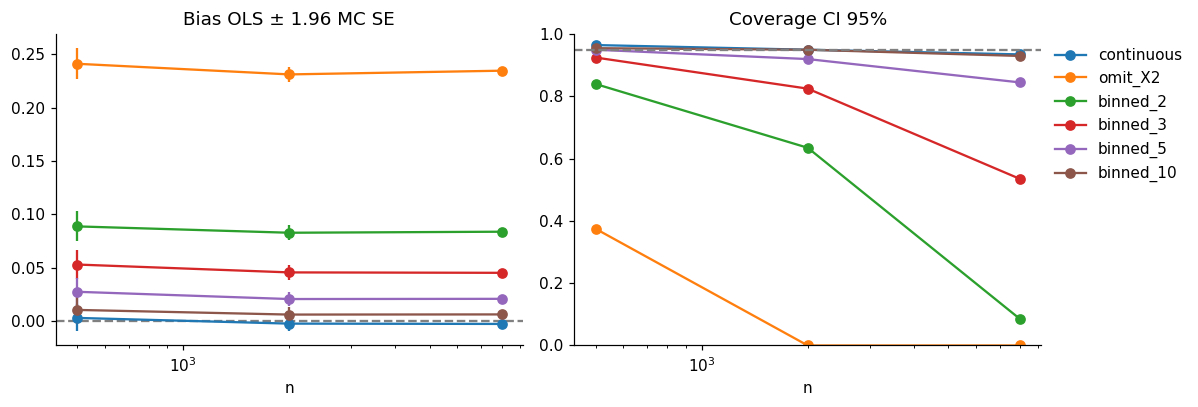

In [28]:
# Biểu đồ T6: cùng trục n, phân biệt số nhóm và hai mốc tham chiếu.
t6 = summary[(summary.scenario == "T6") & (summary.method == "OLS")]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for analysis, group in t6.groupby("analysis", sort=False):
    group = group.sort_values("n")
    axes[0].errorbar(group.n, group.bias, yerr=1.96*group.mc_se_bias, marker="o", label=analysis)
    axes[1].plot(group.n, group.coverage, marker="o", label=analysis)
axes[0].axhline(0, color="gray", ls="--")
axes[1].axhline(.95, color="gray", ls="--")
for ax, title in zip(axes, ("Bias OLS ± 1.96 MC SE", "Coverage CI 95%")):
    ax.set(xscale="log", xlabel="n", title=title)
axes[1].set_ylim(0, 1)
axes[1].legend(frameon=False, bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig(RESULT_DIR / "T6_bias_coverage.png", bbox_inches="tight")
plt.show()


In [29]:
def conclude_type(summary):
    ols = summary[(summary.n == 2000) & (summary.method == "OLS")].set_index(["scenario", "analysis"])
    t6 = [f"{a}: bias {ols.loc[('T6', a), 'bias']:+.3f}"
          for a in ANALYSES["T6"]]
    lines = ["## 9. Kết luận từ lần chạy",
             f"Với R={R}, OLS T0 có bias {ols.loc[('T0','continuous'), 'bias']:+.3f}; "
             f"T1 có bias {ols.loc[('T1','binary'), 'bias']:+.3f}.",
             "Biến định tính biểu diễn đúng bằng dummy/0–1 có thể điều chỉnh confounding tốt. "
             "Hiệu ứng phi tuyến hoặc danh nghĩa cần xét mã hóa theo mức, đồng thời kiểm tra các ô thưa.",
             f"T3b: integer bias {ols.loc[('T3b','integer'), 'bias']:+.3f}, "
             f"dummy {ols.loc[('T3b','dummy'), 'bias']:+.3f}; "
             f"T4: label {ols.loc[('T4','label'), 'bias']:+.3f}, "
             f"dummy {ols.loc[('T4','dummy'), 'bias']:+.3f}.",
             "T6 ở n=2000: " + "; ".join(t6) + ". "
             "Chia nhiều nhóm giữ được nhiều thông tin hơn; tăng n không khôi phục thông tin liên tục bị mất.",
             "Coverage và SE/SD cần đọc cùng MC SE và failure rate, đặc biệt T5. "
             f"Kết quả đang dùng R={R}; R=1000 là mức chạy đầy đủ theo thiết kế."]
    return "\n\n".join(lines)
conclusion = conclude_type(summary)
display(Markdown(conclusion))
(RESULT_DIR / "part_A_conclusions.md").write_text(conclusion, encoding="utf-8")


## 9. Kết luận từ lần chạy

Với R=200, OLS T0 có bias -0.000; T1 có bias +0.004.

Biến định tính biểu diễn đúng bằng dummy/0–1 có thể điều chỉnh confounding tốt. Hiệu ứng phi tuyến hoặc danh nghĩa cần xét mã hóa theo mức, đồng thời kiểm tra các ô thưa.

T3b: integer bias +0.172, dummy +0.000; T4: label -0.133, dummy -0.006.

T6 ở n=2000: continuous: bias -0.002; omit_X2: bias +0.231; binned_2: bias +0.083; binned_3: bias +0.046; binned_5: bias +0.021; binned_10: bias +0.006. Chia nhiều nhóm giữ được nhiều thông tin hơn; tăng n không khôi phục thông tin liên tục bị mất.

Coverage và SE/SD cần đọc cùng MC SE và failure rate, đặc biệt T5. Kết quả đang dùng R=200; R=1000 là mức chạy đầy đủ theo thiết kế.

709